# 01b. Визуальный исследовательский анализ

После [числовых проверок](01_data_analysis.ipynb) мы перешли к графикам, чтобы увидеть, как меняется потребление и какие особенности ряда стоит учитывать в прогнозе. Начали с распределения, затем рассмотрели режимы работы во времени, связи с признаками и отдельные необычные периоды. Данные и лаги загружаются из исходного CSV, поэтому ноутбук можно запустить самостоятельно.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.figure import Figure

from src.data_preparation import ROOT, TARGET_COLUMN, load_raw_data
from src.features import prepare_feature_dataset

raw_data = load_raw_data()
target = raw_data[TARGET_COLUMN]
feature_dataset = prepare_feature_dataset(save=False)

# Пороги и суточные агрегаты рассчитываются здесь для независимого запуска.
q1, q3 = raw_data[TARGET_COLUMN].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
day = (pd.DatetimeIndex(raw_data.index) - pd.Timedelta(minutes=15)).normalize()
daily = raw_data.groupby(day).agg(
    usage=(TARGET_COLUMN, "sum"), week_status=("WeekStatus", "first")
)
weekday_median = daily.loc[daily["week_status"] == "Weekday", "usage"].median()
idle_weekdays = daily[
    (daily["week_status"] == "Weekday") & (daily["usage"] < 0.3 * weekday_median)
]

## Распределение потребления

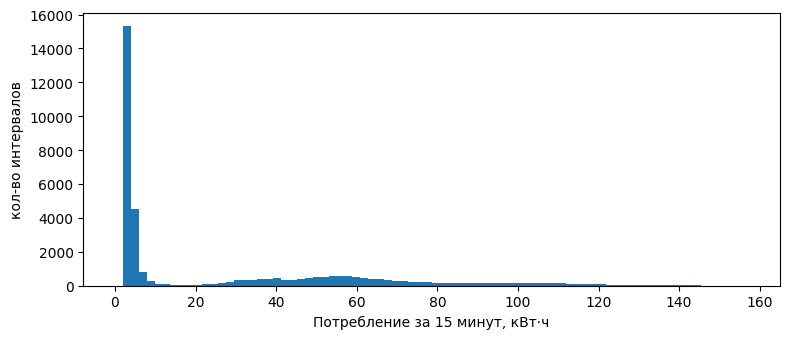

In [2]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(target, bins=80)
ax.set_xlabel("Потребление за 15 минут, кВт·ч")
ax.set_ylabel("кол-во интервалов")
plt.tight_layout()
plt.show()

Гистограмма показывает неоднородное распределение: более половины интервалов имеют потребление ниже 5 кВт·ч, а справа тянется длинный хвост высоких нагрузок. Поэтому одного среднего недостаточно для описания типичного интервала. Нули делают MAPE (средняя абсолютная процентная ошибка) неопределённой, а малые значения могут давать очень большие относительные ошибки даже при небольшом отклонении прогноза. Поэтому основной метрикой выбрали MAE (средняя абсолютная ошибка), которая показывает ошибку в кВт·ч.

## Режимы работы, аномалии и связи

Чтобы дополнить гистограмму, мы выбрали четыре вида визуализаций: недельные графики, календарные профили, корреляционные матрицы и графики необычных периодов. Вместе они помогают понять, когда меняется нагрузка, насколько это связано с календарём и какую информацию дают прошлые измерения. Здесь рассматривается весь ряд; качество прогноза будем оценивать отдельно на временных разбиениях.

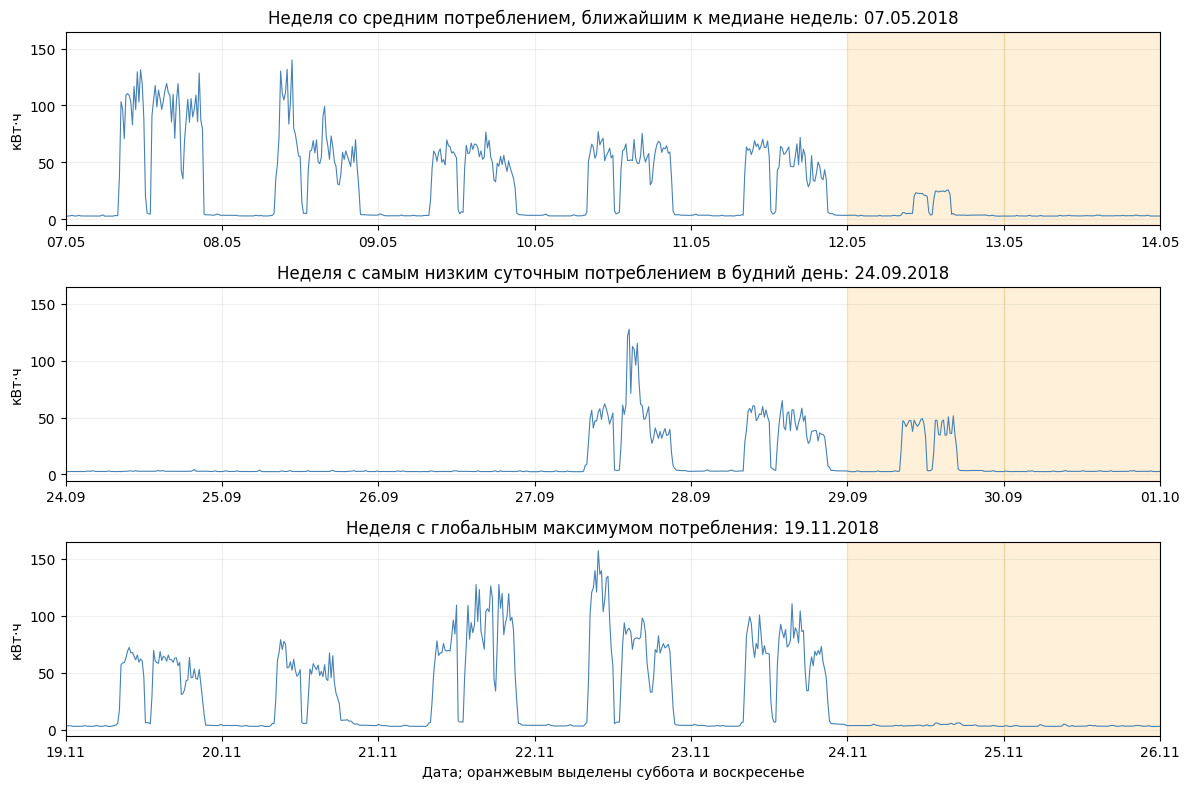

In [3]:
import matplotlib.dates as mdates

figure_dir = ROOT / "results/figures"
figure_dir.mkdir(parents=True, exist_ok=True)

type FigureName = str


def finish_eda_figure(figure: Figure, figure_name: FigureName) -> None:
    figure.tight_layout()
    figure.savefig(figure_dir / figure_name, dpi=150, bbox_inches="tight")
    plt.show()


# Недели выбираются по явным правилам, без ручного отбора красивых примеров.
week_start = day - pd.to_timedelta(day.dayofweek, unit="D")
weekly = target.groupby(week_start).agg(["mean", "count"])
full_weeks = weekly.loc[weekly["count"] == 7 * 96, "mean"]
typical_week = (full_weeks - full_weeks.median()).abs().idxmin()
idle_day = idle_weekdays["usage"].idxmin()
peak_time = target.idxmax()
selected_weeks = [
    ("Неделя со средним потреблением, ближайшим к медиане недель", typical_week),
    (
        "Неделя с самым низким суточным потреблением в будний день",
        idle_day - pd.Timedelta(days=idle_day.dayofweek),
    ),
    (
        "Неделя с глобальным максимумом потребления",
        peak_time.normalize() - pd.Timedelta(days=peak_time.dayofweek),
    ),
]
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharey=True)
for ax, (label, start) in zip(axes, selected_weeks):
    end = start + pd.Timedelta(days=7)
    series = target[(target.index > start) & (target.index <= end)]
    ax.plot(series.index, series, linewidth=0.8, color="steelblue")
    for offset in (5, 6):
        left = start + pd.Timedelta(days=offset)
        ax.axvspan(left, left + pd.Timedelta(days=1), color="orange", alpha=0.15)
    ax.set(title=f"{label}: {start:%d.%m.%Y}", ylabel="кВт·ч", xlim=(start, end))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Дата; оранжевым выделены суббота и воскресенье")
finish_eda_figure(fig, "eda_characteristic_weeks.png")

На недельных графиках видны дневные подъёмы и периоды низкого потребления. Однако календарь объясняет их лишь частично: например, 24–26 сентября потребление оставалось низким, хотя это будни. Поэтому в модель включили не только `WeekStatus` (тип дня: будний или выходной), но и более подробные календарные признаки и недавние измерения. Эти недели иллюстрируют разные режимы; по трём примерам нельзя судить о частоте аномалий.

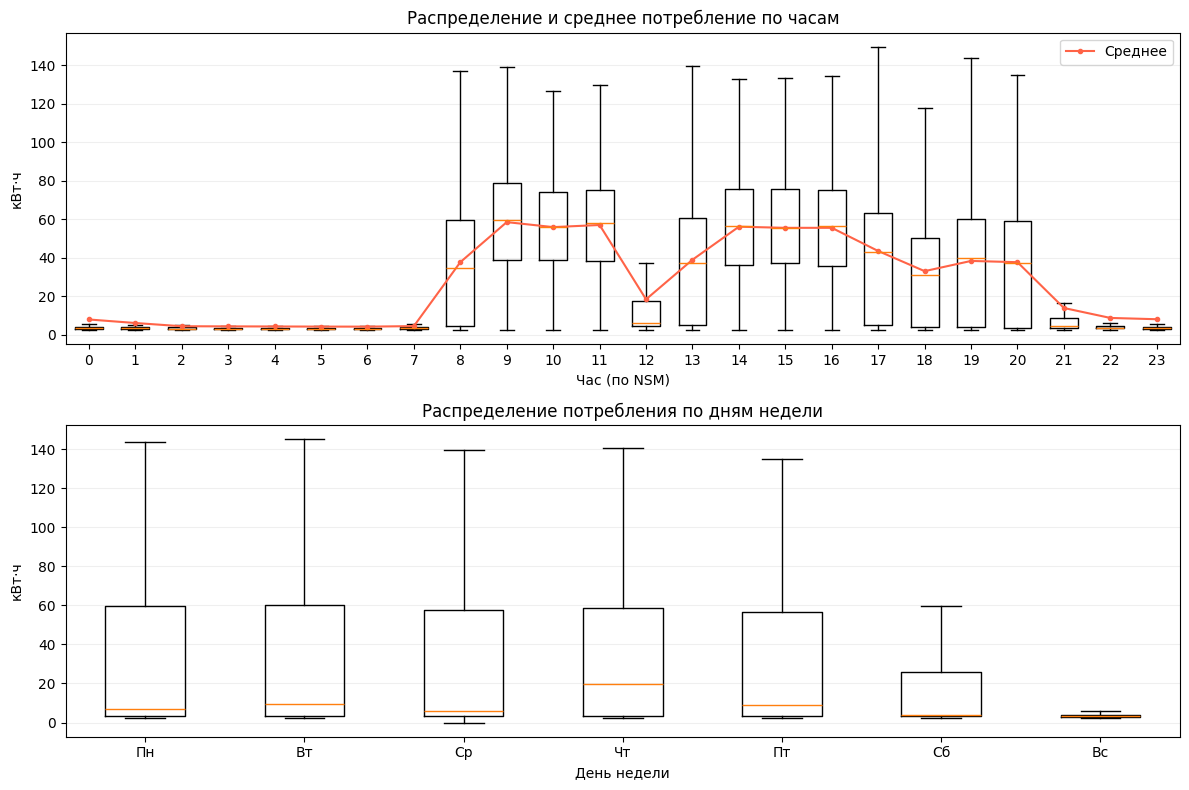

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
hours = list(range(24))
axes[0].boxplot(
    [feature_dataset.loc[feature_dataset["hour"] == h, TARGET_COLUMN] for h in hours],
    positions=hours,
    widths=0.6,
    showfliers=False,
)
hour_mean = feature_dataset.groupby("hour")[TARGET_COLUMN].mean().reindex(hours)
axes[0].plot(hours, hour_mean, "o-", color="tomato", markersize=3, label="Среднее")
axes[0].set(
    title="Распределение и среднее потребление по часам",
    xlabel="Час (по NSM)",
    ylabel="кВт·ч",
)
axes[0].legend()
weekdays = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]
axes[1].boxplot(
    [
        feature_dataset.loc[feature_dataset["day_of_week"] == d, TARGET_COLUMN]
        for d in weekdays
    ],
    tick_labels=["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"],
    showfliers=False,
)
axes[1].set(
    title="Распределение потребления по дням недели",
    xlabel="День недели",
    ylabel="кВт·ч",
)
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
finish_eda_figure(fig, "eda_calendar_distributions.png")

Затем сравнили средние календарные профили с разбросом значений. Средний профиль показывает ночной минимум, дневной рост и снижение около полудня, но boxplot (диаграмма «ящик с усами») показывает, что в дневные часы потребление сильно различается. Значит, час помогает описать режим, но не определяет нагрузку однозначно. Суббота и воскресенье тоже различаются, поэтому добавили `day_of_week` (день недели) наряду с `week_status` (тип дня: будний или выходной).

Коробка показывает межквартильный диапазон, линия внутри — медиану, а усы — границы в пределах 1,5 IQR (межквартильный размах). Чтобы график оставался читаемым, отдельные точки за усами скрыты, но сами наблюдения сохранены в данных. Пики рассмотрены отдельно ниже.

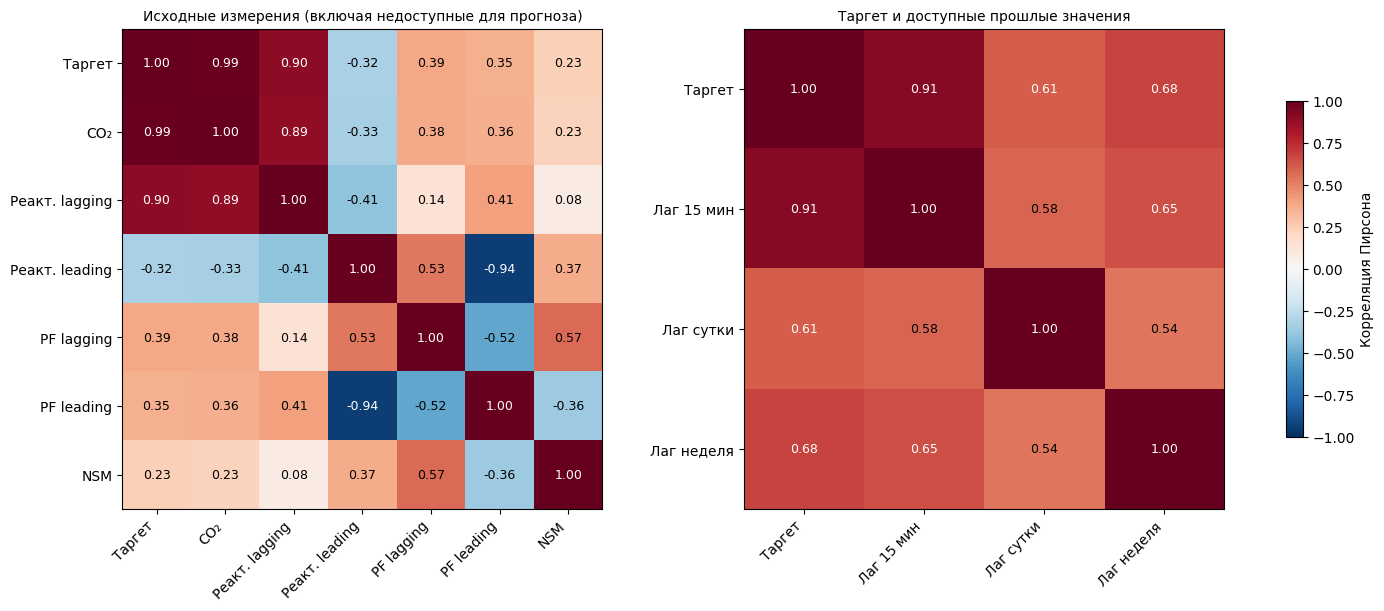

In [5]:
raw_columns = [
    TARGET_COLUMN,
    "CO2(tCO2)",
    "Lagging_Current_Reactive.Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh",
    "Lagging_Current_Power_Factor",
    "Leading_Current_Power_Factor",
    "NSM",
]
lag_columns = [TARGET_COLUMN, "usage_lag_1", "usage_lag_96", "usage_lag_672"]
matrices = [raw_data[raw_columns].corr(), feature_dataset[lag_columns].corr()]
labels = [
    [
        "Таргет",
        "CO₂",
        "Реакт. lagging",
        "Реакт. leading",
        "PF lagging",
        "PF leading",
        "NSM",
    ],
    ["Таргет", "Лаг 15 мин", "Лаг сутки", "Лаг неделя"],
]
fig, axes = plt.subplots(1, 2, figsize=(14, 6), layout="constrained")
for ax, corr, names, title in zip(
    axes,
    matrices,
    labels,
    [
        "Исходные измерения (включая недоступные для прогноза)",
        "Таргет и доступные прошлые значения",
    ],
):
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
    ax.set_yticks(range(len(names)), names)
    ax.set_title(title, fontsize=10)
    for i in range(len(names)):
        for j in range(len(names)):
            value = corr.iloc[i, j]
            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                color="white" if abs(value) > 0.6 else "black",
                fontsize=9,
            )
fig.colorbar(im, ax=axes, shrink=0.7, label="Корреляция Пирсона")
fig.savefig(figure_dir / "eda_correlations.png", dpi=150, bbox_inches="tight")
plt.show()

Корреляционный анализ показал тесную связь потребления с CO₂ и реактивной энергией. Однако эти величины измеряются за прогнозируемый интервал, поэтому использовать их заранее нельзя. Из модели эти измерения исключили. В правой матрице представлены связи с прошлыми значениями потребления. Связь с лагом 15 минут (≈0,91) сильнее, чем с суточным (≈0,61) и недельным (≈0,68). Поэтому за отправную точку взяли прогноз по последнему наблюдению и затем проверили, помогают ли дополнительные лаги. Более высокая связь с недельным лагом согласуется с недельным режимом, но сама корреляция не доказывает ни причинность, ни улучшение прогноза.

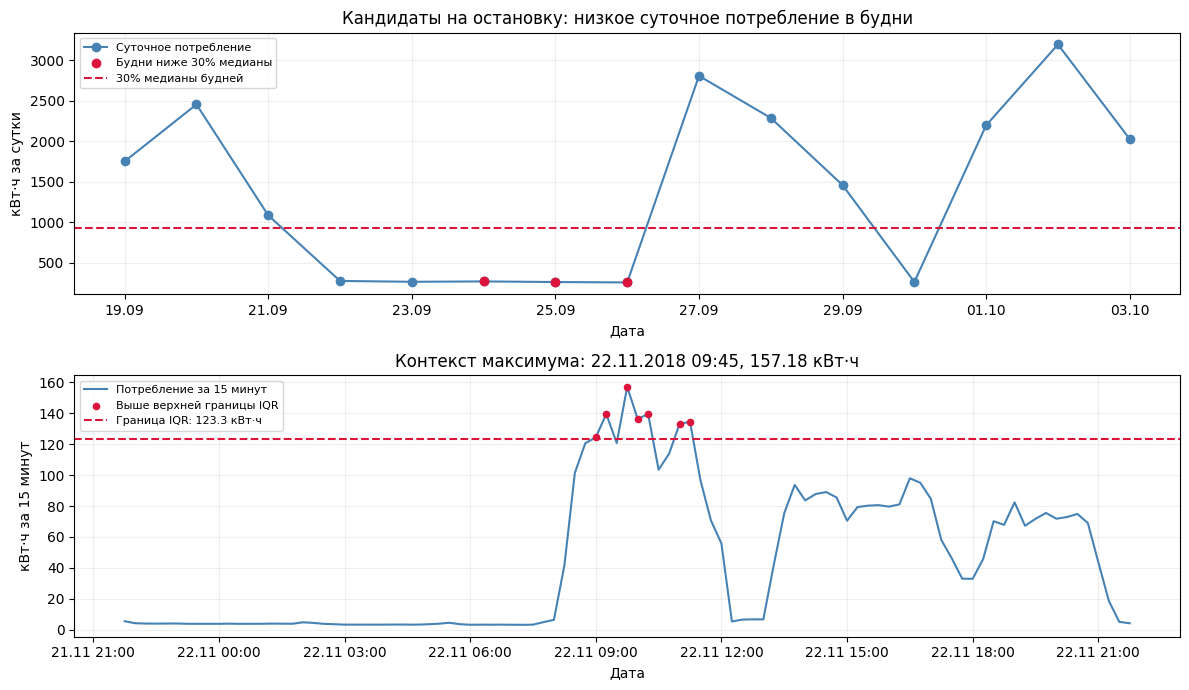

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
# Контекст вокруг самого низкого буднего дня: сравнение с суточным порогом.
window = daily.loc[idle_day - pd.Timedelta(days=7) : idle_day + pd.Timedelta(days=7)]
axes[0].plot(
    window.index, window["usage"], "o-", color="steelblue", label="Суточное потребление"
)
flagged = idle_weekdays.loc[idle_weekdays.index.isin(window.index)]
axes[0].scatter(
    flagged.index,
    flagged["usage"],
    color="crimson",
    zorder=3,
    label="Будни ниже 30% медианы",
)
axes[0].axhline(
    0.3 * weekday_median, color="crimson", linestyle="--", label="30% медианы будней"
)
axes[0].set(
    title="Кандидаты на остановку: низкое суточное потребление в будни",
    ylabel="кВт·ч за сутки",
)
# Интервальные пики: отдельный масштаб времени и единицы.
local = target.loc[
    peak_time - pd.Timedelta(hours=12) : peak_time + pd.Timedelta(hours=12)
]
axes[1].plot(local.index, local, color="steelblue", label="Потребление за 15 минут")
peaks = local[local > upper]
axes[1].scatter(
    peaks.index,
    peaks,
    color="crimson",
    s=20,
    zorder=3,
    label="Выше верхней границы IQR",
)
axes[1].axhline(
    upper, color="crimson", linestyle="--", label=f"Граница IQR: {upper:.1f} кВт·ч"
)
axes[1].set(
    title=f"Контекст максимума: {peak_time:%d.%m.%Y %H:%M}, {target.max():.2f} кВт·ч",
    ylabel="кВт·ч за 15 минут",
)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m"))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d.%m %H:%M"))
for ax in axes:
    ax.legend(fontsize=8, loc="upper left")
    ax.grid(alpha=0.2)
    ax.set_xlabel("Дата")
finish_eda_figure(fig, "eda_anomaly_context.png")

Наконец, отдельно рассмотрели низкое потребление и пики. 24–26 сентября образуют серию будних дней с низким суточным потреблением; минимум среди таких дней приходится на 26 сентября и составляет 259,46 кВт·ч. Можно предположить остановку или сокращённый режим работы, но в данных причина не указана. Максимум за 15 минут — 157,18 кВт·ч — наблюдается 22 ноября в 09:45. Соседние интервалы помогают отличать единичный скачок от периода повышенной нагрузки. Превышение порога IQR само по себе не доказывает ошибку измерения, поэтому сохранили эти наблюдения.